<a href="https://colab.research.google.com/github/Radiat09/colab/blob/main/Python_Final_Exam_Question_Solution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



# AI Programming with Python Final Exam

**Name: MD Radiat Hossain Ridoy**

**Course Email:**  radiathossainr@gmail.com


## End of Assignment

Before submitting:
- Must watch the Exam Instructions Video
- Run all cells from top to bottom.  
- Check that all answer sections are filled.  
- Instruction video অনুযায়ী আমাদের দেয়া Colab ফাইলটি থেকে প্রথম একটি Save copy in drive করে নিবা। এরপর Google colab এর মধ্যে কোডগুলো করবে এবং সেই ফাইলটি ‘Anyone with the link’ & ‘View’ Access দিয়ে ফাইলটির Shareble Link টি সাবমিট করবে।

# 0) Starter Code (Run First)

In [ ]:
# You must run this code and use this dataset for all questions
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)
num_students = 50

# Student data
student_ids = np.arange(201, 201 + num_students)
student_ages = np.random.randint(15, 22, num_students)
student_scores = np.random.randint(40, 100, num_students)
student_attendance = np.random.randint(60, 100, num_students)  # percentage

departments_list = [
    "Science",
    "Commerce",
    "Arts",
    "Computer Science",
    "Mathematics",
    "English",
    "Physics",
    "Chemistry",
    "Biology",
    "Economics"
]

student_departments = np.random.choice(departments_list, num_students)

grade_conditions = [
    student_scores >= 80,
    (student_scores >= 65) & (student_scores < 80),
    (student_scores >= 50) & (student_scores < 65),
    student_scores < 50
]
grade_values = ["A", "B", "C", "F"]
student_grades = np.select(grade_conditions, grade_values, default="F")

# Create DataFrame
data = pd.DataFrame({
    "student_id": student_ids,
    "student_age": student_ages,
    "score": student_scores,
    "attendance": student_attendance,
    "department": student_departments,
    "grade": student_grades
})

# Save dataset
data.to_csv("school_data.csv", index=False)

# Question 01: [ Marks 10 ]

Use NumPy arrays from the score and attendance columns. Print both arrays and display:

* Data type
* Number of dimensions
* Shape
* Total number of elements

# Write Answer 01:


In [ ]:

print("Student Score: ------------------------")
print("DataType   -    -   -   : ",type(student_scores))
print("Number of Dimensions    : ",student_scores.ndim)
print("Shape  -    -      -    : ",student_scores.shape)
print("Total Number of elements: ",student_scores.size)

print("\n")
print("Student Attendance:-------------------")
print("DataType   -    -   -   : ",type(student_attendance))
print("Number of Dimensions    : ",student_attendance.ndim)
print("Shape  -    -      -    :",student_attendance.shape)
print("Total Number of elements: ",student_attendance.size)

Student Score: ------------------------
DataType   -    -   -   :  <class 'numpy.ndarray'>
Number of Dimensions    :  1
Shape  -    -      -    :  (50,)
Total Number of elements:  50


Student Attendance:-------------------
DataType   -    -   -   :  <class 'numpy.ndarray'>
Number of Dimensions    :  1
Shape  -    -      -    : (50,)
Total Number of elements:  50


# Question 02: [ Marks 10 ]

## Using NumPy functions on :

* Find the maximum and minimum score
* Calculate the average score
* Calculate the average attendance

Then, extract students who:

* Have a score greater than the average score

Print:

* The filtered score array

## Write Answer 02:


In [ ]:
max_sco = student_scores.max()
min_sco = student_scores.min()
avg_sco = student_scores.mean()

avg_att = student_attendance.mean()

filtered_score= student_scores[student_scores>avg_sco]



print("Maximum Score: ",max_sco)
print("Minimum Score: ",min_sco)
print("Average Attendance: ",avg_att)
print("Filtered Scores   : ",filtered_score)

Maximum Score:  99
Minimum Score:  41
Average Attendance:  79.58
Filtered Scores   :  [76 90 78 99 89 97 92 86 99 83 86 74 75 89 79 93 81 93 68 83 73 75 70 87]


# Question 03: [Marks 10]

##
Load the school_data.csv file into a Pandas DataFrame.

* Display the first 3 rows
* Show dataset information using .info()
* Display summary statistics using .describe()

Then filter the dataset to include only:

* student_id, student_age, department, grade

Select students whose age is between 16 and 20, sort them by student_id, and display the last 3 rows of the result.


## Write Answer 03:

In [ ]:
df = pd.read_csv("school_data.csv")

print("-----------------------------First 3 rows: -----------------------------------")
print(df.head(3))
print("\n \n ------------------------------ INFO: --------------------------------------")
print(df.info())
print("\n \n-------------------------------- Summary--------------------------------------")
print(df.describe())
print("\n \n------------------------------ Filtered Dataset-------------------------------")

filtered_df = df[["student_id","student_age","department","grade"]]

filtered_age_df = filtered_df[(df['student_age'] >= 16) & (df['student_age'] <= 20)]

sorted_df = filtered_age_df.sort_values(by='student_id').tail(3)

sorted_df

-----------------------------First 3 rows: -----------------------------------
   student_id  student_age  score  attendance department grade
0         201           21     76          73    Physics     B
1         202           18     90          82    Physics     A
2         203           19     46          99    Biology     F

 
 ------------------------------ INFO: --------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   student_id   50 non-null     int64 
 1   student_age  50 non-null     int64 
 2   score        50 non-null     int64 
 3   attendance   50 non-null     int64 
 4   department   50 non-null     object
 5   grade        50 non-null     object
dtypes: int64(4), object(2)
memory usage: 2.5+ KB
None

 
-------------------------------- Summary--------------------------------------
       student_id  stu

,student_id,student_age,department,grade
45,246,18,Biology,C
47,248,18,Science,A
49,250,17,Economics,F



# Question 04: [ Marks 10 ]

##
Using .loc:

* Increase the score by 10% for students in "Computer Science" and "Mathematics" departments
* Increase the score by 5% for all other departments
* Cap the score at 100 (no score should exceed 100 after the raise)

Then print a DataFrame that includes:

* student_id, department, previous_score, new_score, score_increase


## Write Answer 04:

In [ ]:

df['previous_score'] = df['score']


cs_math_filter = df['department'].isin(['Computer Science', 'Mathematics'])

other_departments = [
    "Science", "Commerce", "Arts", "English",
    "Physics", "Chemistry", "Biology", "Economics"
]
other_filter = df['department'].isin(other_departments)

#1
df.loc[cs_math_filter, 'score'] = df.loc[cs_math_filter, 'score'] * 1.10

#2
df.loc[other_filter, 'score'] = df.loc[other_filter, 'score'] * 1.05

#3
df.loc[df['score'] > 100, 'score'] = 100


df['new_score'] = df['score']
df['score_increase'] = df['new_score'] - df['previous_score']

#4
result_df = df[['student_id', 'department', 'previous_score', 'new_score', 'score_increase']]
print(result_df.to_string(index=False))

 student_id       department  previous_score  new_score  score_increase
        201          Physics      100.000000 100.000000        0.000000
        202          Physics      100.000000 100.000000        0.000000
        203          Biology       74.929153  78.675610        3.746458
        204        Economics       97.733678 100.000000        2.266322
        205        Economics       78.186942  82.096289        3.909347
        206             Arts      100.000000 100.000000        0.000000
        207          Physics       92.846994  97.489343        4.642350
        208          Science       70.042469  73.544592        3.502123
        209 Computer Science      100.000000 100.000000        0.000000
        210 Computer Science      100.000000 100.000000        0.000000
        211      Mathematics      100.000000 100.000000        0.000000
        212          Physics      100.000000 100.000000        0.000000
        213          Physics      100.000000 100.000000        0

# Question 05: [ Marks 10 ]

Using Matplotlib, create a bar chart that shows the average score per department.

* X-axis: Department names
* Y-axis: Average score
* Add a title: "Average Score by Department"
* Display the chart

## Answer 05:

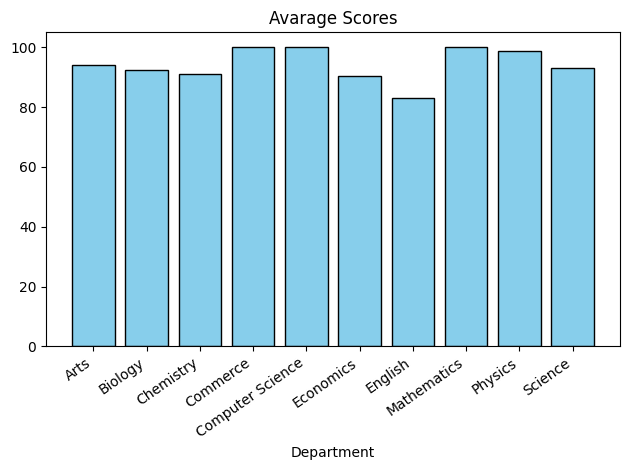

In [ ]:
import matplotlib.pyplot as plt

avg_score = df.groupby("department")["score"].mean()
avg_score

plt.bar(avg_score.index, avg_score.values, color='skyblue', edgecolor='black')


plt.title("Avarage score by department")
plt.xlabel("Department")
plt.title("Avarage Scores")


plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.show()

# Question 06: [ Marks 10 ]

Using Matplotlib, create a histogram of the score column.

* Use 10 bins
* Add a title: "Distribution of Student Scores"
* Label X-axis as "Score" and Y-axis as "Number of Students"
* Display the chart

## Answer 06:

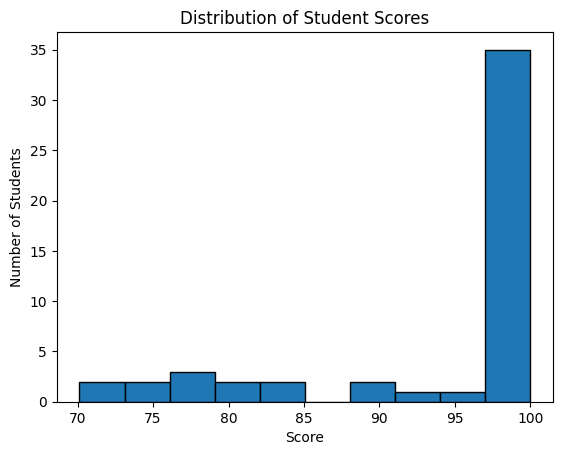

In [ ]:
import matplotlib.pyplot as plt


plt.hist(df["score"], bins=10,edgecolor='black')


plt.title("Distribution of Student Scores")
plt.xlabel("Score")
plt.ylabel("Number of Students")


plt.show()


# Question 07: [ Marks 10 ]

Using Matplotlib, create a scatter plot to visualize the relationship between attendance and score.

* X-axis: Attendance (%)
* Y-axis: Score
* Add a title: "Attendance vs Score"
* Label both axes properly
* Display the chart

## Answer 07:


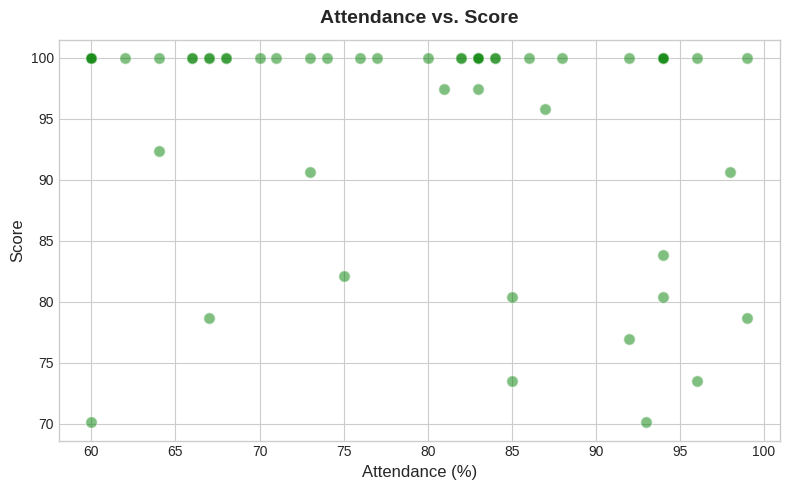

In [ ]:
import matplotlib.pyplot as plt


plt.style.use('seaborn-v0_8-whitegrid')

plt.figure(figsize=(8, 5))

plt.scatter(
    x=df["attendance"],
    y=df["score"],
    color='green',
    alpha=0.5,      # Makes dense clusters visible
    edgecolors='w', # Adds a clean white border around points
    s=70            # Marker size
    )

plt.title("Attendance vs. Score", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Attendance (%)", fontsize=12)
plt.ylabel("Score", fontsize=12)


plt.tight_layout()
plt.show()

# Question 08: [ Marks 10 ]

Using Seaborn, create a boxplot / barplot that shows the distribution of score across different grade categories.

* X-axis: Grade
* Y-axis: Score
* Add a title: "Score Distribution by Grade"
* Display the chart

## Answer 08:

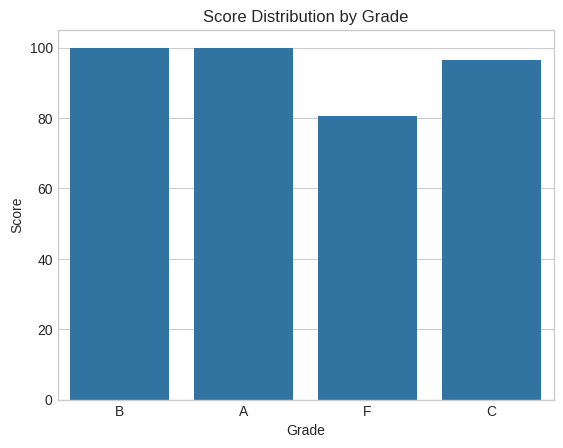

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


sns.barplot(data=df, x="grade", y="score", errorbar=None)


plt.title("Score Distribution by Grade")
plt.xlabel("Grade")
plt.ylabel("Score")

plt.show()

# Question 09: [ Marks 10 ]

Using Seaborn, create a countplot showing the number of students in each department.

* Add a title: "Number of Students per Department"
* Display the chart

# Write Answer 09:

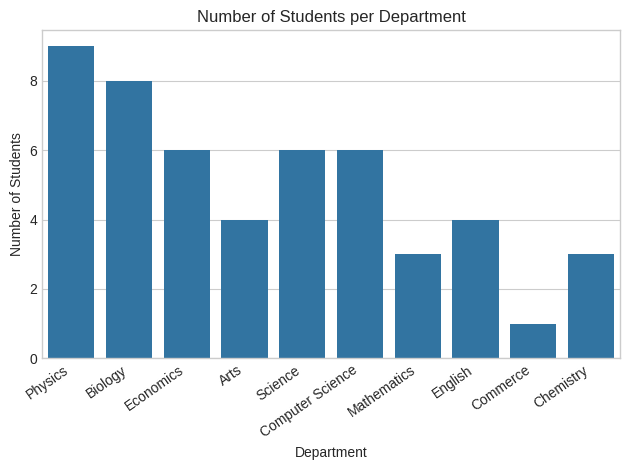

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns



sns.countplot(data=df, x="department")


plt.title("Number of Students per Department")
plt.xlabel("Department")
plt.ylabel("Number of Students")

plt.xticks(rotation=35, ha="right")


plt.tight_layout()
plt.show()

# Question 10: [ Marks 10 ]

create a scatter plot showing attendance vs score.

* Color the points by department
* Add a title: "Attendance vs Score by Department"
* Label X-axis as "Attendance (%)" and Y-axis as "Score"
* Display the chart

# Write Answer 10:

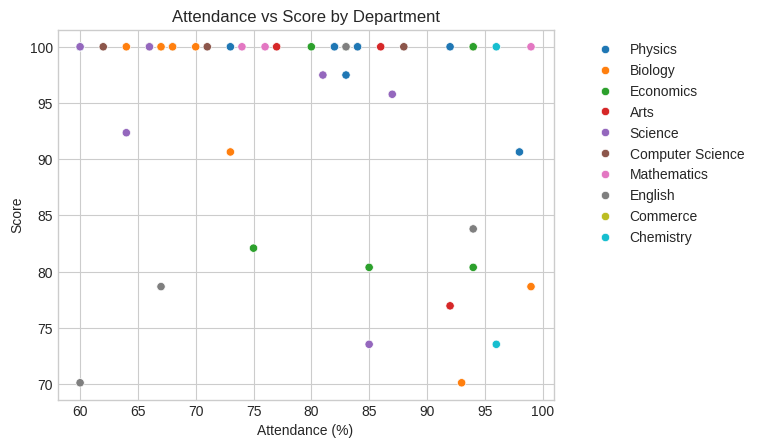

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


sns.scatterplot(data=df, x="attendance", y="score", hue="department")


plt.title("Attendance vs Score by Department")
plt.xlabel("Attendance (%)")
plt.ylabel("Score")

plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.show()